## Compare traditional vs. compositional MFA estimation across both toy network and TCA cycle
Generates the main paper figures flux residuals (Fig. 3), MSE difference heatmap (Fig. 5), and the sensitivity analysis grid plot.

In [1]:
import pickle
from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

In [2]:
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [3]:
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = '#D27720'
ILR =  '#038C7F'

# Fig. 3 Ground truth flux

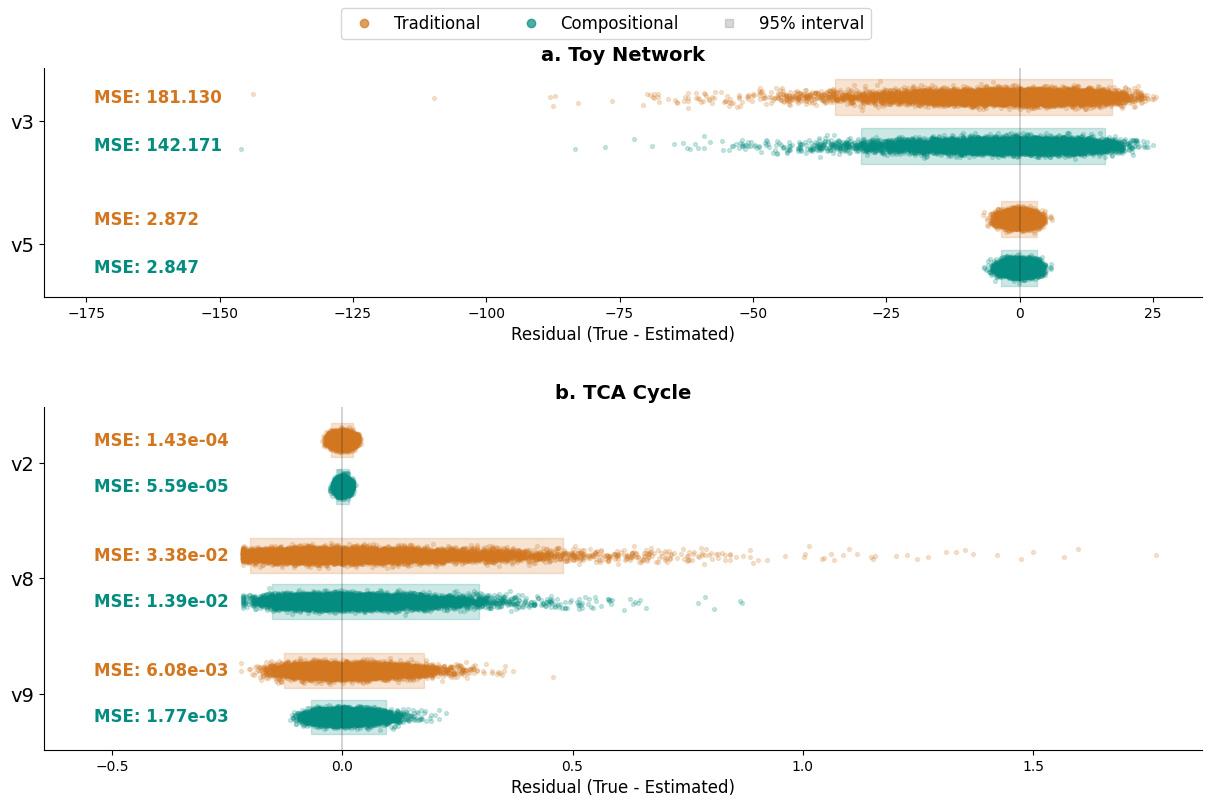

In [4]:
# --- 1. DATA LOADING & RESIDUALS ---
# (Assumes RESULTS_DIR_TOY and RESULTS_DIR_TCA are defined as in previous steps)
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    est_toy = pickle.load(f)

true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    est_tca = pickle.load(f)

res_trad_toy = (true_flux_toy[None, [2, 4]] - est_toy["trad"][:, [4, 5]])
res_comp_toy = (true_flux_toy[None, [2, 4]] - est_toy["ilr"][:, [4, 5]])
mse_trad_toy = (res_trad_toy ** 2).mean(axis=(0))
mse_comp_toy = (res_comp_toy ** 2).mean(axis=(0))

true_ref_tca = np.array([true_flux_tca[k] for k in ["v8", "v2", "v9"]])
res_trad_tca = est_tca["trad"][:, :] - true_ref_tca[None, :]
res_comp_tca = est_tca["ilr"][:, :] - true_ref_tca[None, :]
mse_trad_tca = (res_trad_tca ** 2).mean(axis=(0))
mse_comp_tca = (res_comp_tca ** 2).mean(axis=(0))

# --- 2. PLOTTING ---

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), 
                               gridspec_kw={'height_ratios': [2, 3], 'hspace': 0.1}, layout="constrained")

def draw_scatter_with_95_interval(ax, trad_data, comp_data, labels):
    positions = np.arange(len(labels))[::-1]
    
    for i, pos in enumerate(positions):
        data_pairs = [
            (trad_data[i], pos + 0.2, TRAD, 'Traditional'),
            (comp_data[i], pos - 0.2, ILR, 'Compositional')
        ]
        
        for data, y_pos, color, label in data_pairs:
            # Calculate 95% Interval (2.5% to 97.5%)
            lower = np.percentile(data, 2.5)
            upper = np.percentile(data, 97.5)
            
            # Draw the 95% Sample Space Box
            rect = Rectangle((lower, y_pos - 0.15), upper - lower, 0.3, 
                             linewidth=1, edgecolor=color, facecolor=color, alpha=0.2)
            ax.add_patch(rect)
            
            # Draw Jittered Scatter Points
            jitter = np.random.normal(y_pos, 0.03, size=len(data))
            ax.scatter(data, jitter, color=color, s=8, alpha=0.20, label=label if i==0 else "")
            

    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=14)
    ax.axvline(0, color='black', linestyle='-', alpha=0.2, lw=1.2)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

def mse_text(ax, mse_trad, mse_comp, labels, left_padding=0.15, fmt=".2g"):
    positions = np.arange(len(labels))[::-1]
    x_min, x_max = ax.get_xlim()
    
    # Calculate new x_min to create empty space on the left
    total_range = x_max - x_min
    new_x_min = x_min - (total_range * left_padding)
    ax.set_xlim(new_x_min, x_max)
    
    # Place text in the newly created space
    # text_x is slightly to the right of the new x_min
    text_x = new_x_min + (total_range * 0.05)
    
    for i, pos in enumerate(positions):
        ax.text(text_x, pos + 0.2, f"MSE: {mse_trad[i]:{fmt}}", 
                color=TRAD, fontsize=12, va='center', fontweight='bold')
        ax.text(text_x, pos - 0.2, f"MSE: {mse_comp[i]:{fmt}}", 
                color=ILR, fontsize=12, va='center', fontweight='bold')

# Render Toy Network
draw_scatter_with_95_interval(ax1, 
                              [res_trad_toy[:, 0], res_trad_toy[:, 1]], 
                              [res_comp_toy[:, 0], res_comp_toy[:, 1]], 
                              ["v3", "v5"])
mse_text(ax1, mse_trad_toy, mse_comp_toy, ["v3", "v5"], fmt=".3f")
ax1.set_title("a. Toy Network", fontweight='bold', fontsize=14)
ax1.set_xlabel("Residual (True - Estimated)", fontsize=12)

# Render TCA Cycle
draw_scatter_with_95_interval(ax2, 
                              [res_trad_tca[:, 1], res_trad_tca[:, 0], res_trad_tca[:, 2]], 
                              [res_comp_tca[:, 1], res_comp_tca[:, 0], res_comp_tca[:, 2]], 
                              ["v2", "v8", "v9"],
                              )
# ax2.set_xlim(-0.25,1)
mse_text(ax2, 
        [mse_trad_tca[1], mse_trad_tca[0], mse_trad_tca[2]], 
        [mse_comp_tca[1], mse_comp_tca[0], mse_comp_tca[2]], 
        ["v2", "v8", "v9"],
        fmt = ".2e",
        )
ax2.set_title("b. TCA Cycle", fontweight='bold', fontsize=14)
ax2.set_xlabel("Residual (True - Estimated)", fontsize=12)

# Custom legend
custom_marker = [
    Line2D([0], [0], color=TRAD, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=ILR, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color="grey", marker="s", linestyle="", markersize=6, alpha = 0.30),
]
fig.legend(custom_marker, ["Traditional", "Compositional", "95% interval"], fontsize=12, loc="outside upper center", ncols=3) #, bbox_to_anchor=(1.1,0.6)
plt.savefig(PLOT_DIR / '3_flux_residuals.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.savefig(PLOT_DIR / '3_flux_residuals.svg', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()

In [5]:
print("toy trad:", mse_trad_toy)
print("toy comp:", mse_comp_toy)

print("tca trad:", mse_trad_tca)
print("tca comp:", mse_comp_tca)

print(f"Presentage decrease: {((mse_trad_toy-mse_comp_toy)/mse_trad_toy)*100}")
print(f"Presentage decrease: {((mse_trad_tca-mse_comp_tca)/mse_trad_tca)*100}")
print(f"avarge improvement {np.mean(np.array([21.50901, 0.881893, 59.013947, 60.801823, 70.967606]))}")

toy trad: [181.12988     2.8719678]
toy comp: [142.17064   2.84664]
tca trad: [0.03382441 0.00014272 0.00608302]
tca comp: [1.3863293e-02 5.5945169e-05 1.7660466e-03]
Presentage decrease: [21.50901   0.881893]
Presentage decrease: [59.013947 60.801823 70.967606]
avarge improvement 42.634855800000004


# Fig. 5 Sensitivity analysis

In [6]:
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
free_fluxes_toy = np.load(RESULTS_DIR_TOY / "free_fluxes_grid.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes_grid.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

resid_trad_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["trad"][:, :, [4, 5]])
resid_ilr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["ilr"][:, :, [4, 5]])

mse_trad_toy = (resid_trad_toy ** 2).mean(axis=(0, 1))
mse_ilr_toy = (resid_ilr_toy ** 2).mean(axis=(0, 1))

diff_flux_toy = ((resid_trad_toy ** 2).mean(axis=1) - (resid_ilr_toy ** 2).mean(axis=1))

In [7]:
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
free_fluxes_tca = jnp.load(RESULTS_DIR_TCA / "free_fluxes_grid.npy", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes_grid.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

resid_trad_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["trad"][:, :, :])
resid_ilr_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["ilr"][:, :, :])

mse_trad_tca = (resid_trad_tca ** 2).mean(axis=(0, 1))
mse_ilr_tca = (resid_ilr_tca ** 2).mean(axis=(0, 1))

diff_flux_tca= ((resid_trad_tca ** 2).mean(axis=1) - (resid_ilr_tca ** 2).mean(axis=1))

free_flux_numbers = jnp.array([8,2,9])

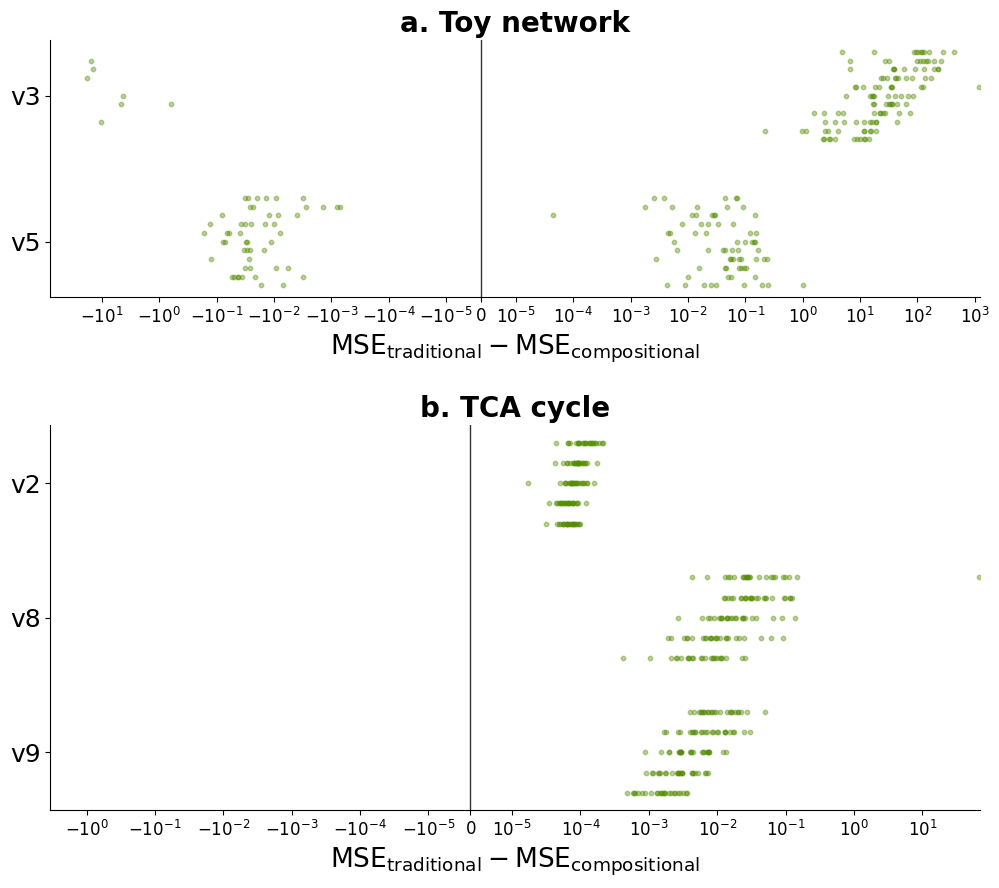

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), 
                               gridspec_kw={'height_ratios': [2, 3], 'hspace': 0.4})

def draw_scatter_ordered(ax, diff_data, flux_val, labels):
    positions = np.arange(len(labels))[::-1]
    
    for i, pos in enumerate(positions):
        xmin = flux_val[i].min()
        xmax = flux_val[i].max()
        a, b = -0.3, 0.3
        flux_scaled = a + (flux_val[i] - xmin) * (b - a) / (xmax - xmin)
        data_pairs = [
            (diff_data[i], pos + flux_scaled)
        ]
        for data, y_pos in data_pairs:            
            ax.scatter(data, y_pos, color=OLIVE, s=10, alpha=0.40)
    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=18)
    ax.axvline(0, color='black', linestyle='-', alpha=0.8, lw=1)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Render Toy Network
draw_scatter_ordered(ax1, 
                    [diff_flux_toy[:, 0], diff_flux_toy[:, 1]], 
                    [free_fluxes_toy[:, 0], free_fluxes_toy[:, 1]], 
                    ["v3", "v5"])
ax1.set_title("a. Toy network", fontweight='bold', fontsize=20)
ax1.set_xlabel(r"$\mathrm{MSE_{traditional}} - \mathrm{MSE_{compositional}}$", fontsize=19)
ax1.set_xscale("symlog", linthresh=1e-5, linscale=0.55)
ax1.tick_params(axis="x", labelsize=12)

draw_scatter_ordered(ax2, 
                    [diff_flux_tca[:, 1], diff_flux_tca[:, 0], diff_flux_tca[:, 2]], 
                    [free_fluxes_tca[:, 1], free_fluxes_tca[:, 0], free_fluxes_tca[:, 2]], 
                    ["v2","v8", "v9"])
ax2.set_title("b. TCA cycle", fontweight='bold', fontsize=20)
ax2.set_xlabel(r"$\mathrm{MSE_{traditional}} - \mathrm{MSE_{compositional}}$", fontsize=19)
ax2.set_xscale("symlog", linthresh=1e-5, linscale=0.55)
ax2.tick_params(axis="x", labelsize=12)

plt.savefig(PLOT_DIR /'5_mse_difference.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()

In [9]:
print(f"Mean difference for Toy network: \nv3: {diff_flux_toy.mean(axis=0)[0]}, v5: {diff_flux_toy.mean(axis=0)[1]}\n")
print(f"Mean difference for TCA cycle: \nv2: {diff_flux_tca.mean(axis=0)[1]}, v8: {diff_flux_tca.mean(axis=0)[0]}, v9: {diff_flux_tca.mean(axis=0)[2]}")

Mean difference for Toy network: 
v3: 59.26300811767578, v5: 0.030427996069192886

Mean difference for TCA cycle: 
v2: 8.668412192491814e-05, v8: 0.5668444037437439, v9: 0.006471242289990187
